In [1]:
import os
import scanpy as sc
import pandas as pd
import anndata as ad
import numpy as np
import cell2location
from cell2location.models import RegressionModel

/data/pinello/SHARED_SOFTWARE/envs/zl002_envs/zl_cell2location/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
in_dir = '../../results/03_kidney_atlas/02_create_anndata'
out_dir = '../../results/03_kidney_atlas/03_run_cell2location'

os.makedirs(out_dir, exist_ok=True)

In [3]:
adata = sc.read_h5ad(f'{in_dir}/adata.h5ad')

In [4]:
sc.pp.calculate_qc_metrics(adata, inplace=True)

In [5]:
# filter genes
sc.pp.filter_genes(adata, min_cells=int(0.05 * adata.n_obs))  # keep genes expressed in at least 5% of cells

In [6]:
adata

AnnData object with n_obs × n_vars = 203702 × 9572
    obs: 'library', 'nCount_RNA', 'nFeature_RNA', 'percent.er', 'percent.mt', 'degen.score', 'aEpi.score', 'aStr.score', 'cyc.score', 'matrisome.score', 'collagen.score', 'glycoprotein.score', 'proteoglycan.score', 'S.Score', 'G2M.Score', 'Phase', 'experiment', 'experiment.short', 'specimen', 'condition.long', 'condition.l1', 'condition.l2', 'condition.l3', 'patient', 'region.l1', 'region.l2', 'percent.cortex', 'percent.medulla', 'sex', 'race', 'tissue_type', 'assay', 'location', 'laterality', 'snDrop_predicted_subclass', 'snDrop_prediction_score', 'pagoda_k50_infomap', 'pagoda_k100_infomap', 'pagoda_k200_infomap', 'pagoda_k500_infomap', 'clusters', 'subclass.full', 'subclass.l3', 'subclass.l2', 'subclass.l1', 'state.l2', 'state.l1', 'class', 'structure', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_

In [5]:
adata.obs['subclass.l1'] = adata.obs['subclass.l1'].astype(str)
adata.obs['subclass.l2'] = adata.obs['subclass.l2'].astype(str)

In [6]:
adata = adata[adata.obs['subclass.l1'] != "nan"].copy()
adata = adata[adata.obs['subclass.l2'] != "nan"].copy()

adata.obs['experiment_short'] = adata.obs['experiment.short']
adata.obs['condition_long'] = adata.obs['condition.long']
adata.obs['subclass_l1'] = adata.obs['subclass.l1']
adata.obs['subclass_l2'] = adata.obs['subclass.l2']

adata.obs['subclass_l1'] = adata.obs['subclass_l1'].astype('category')
adata.obs['subclass_l2'] = adata.obs['subclass_l2'].astype('category')

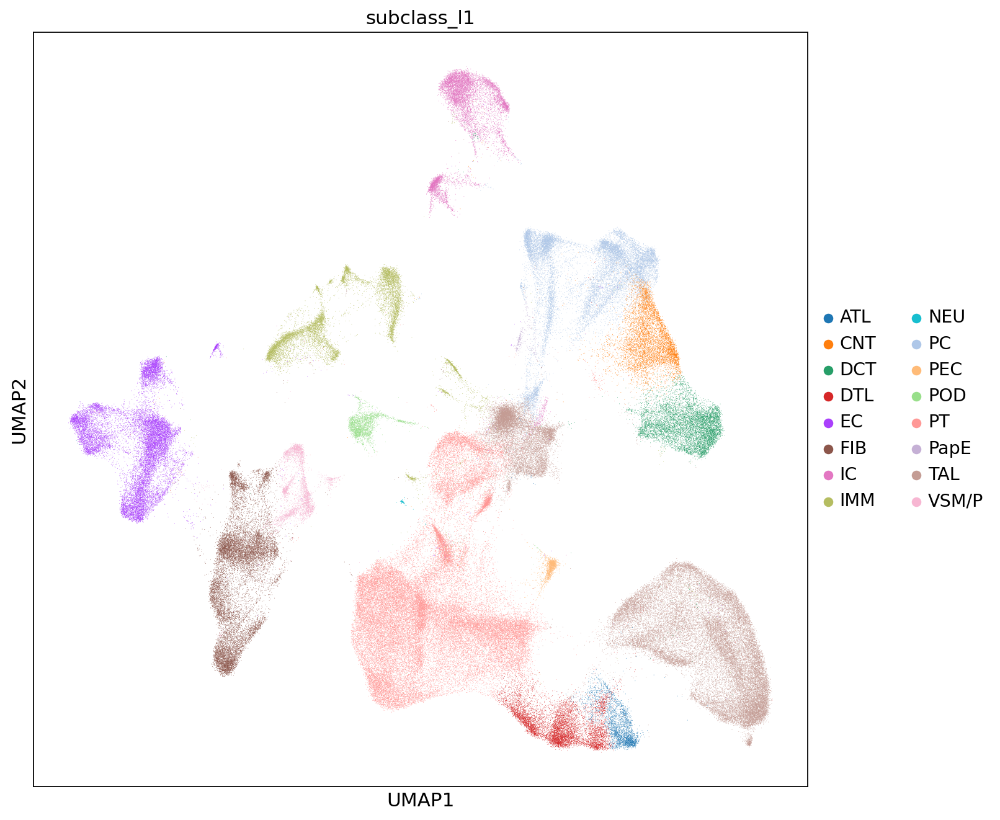

In [7]:
sc.set_figure_params(figsize=(10, 10))
sc.pl.umap(adata, color='subclass_l1')

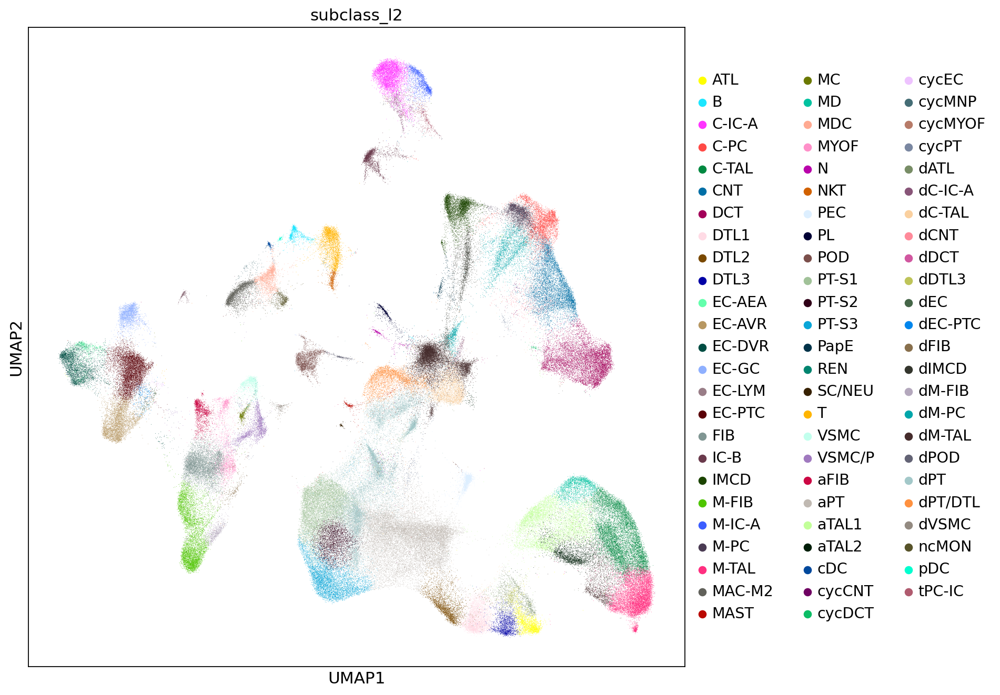

In [8]:
sc.set_figure_params(figsize=(10, 10))
sc.pl.umap(adata, color='subclass_l2')

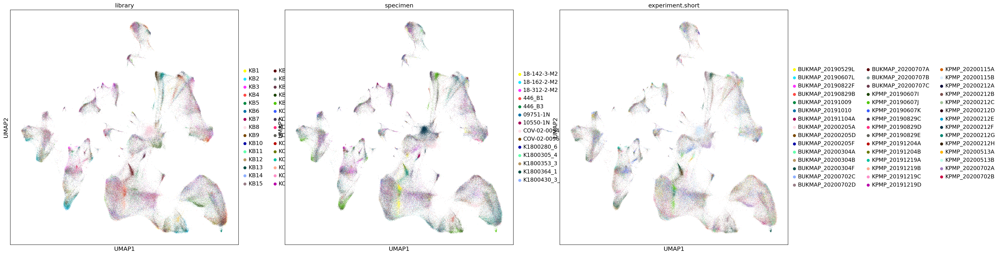

In [9]:
sc.pl.umap(adata, color=['library', 'specimen', 'experiment.short'])

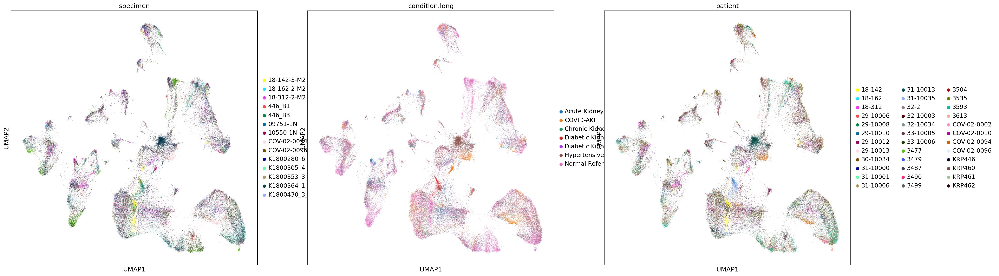

In [10]:
sc.pl.umap(adata, color=['specimen', 'condition.long', 'patient'])

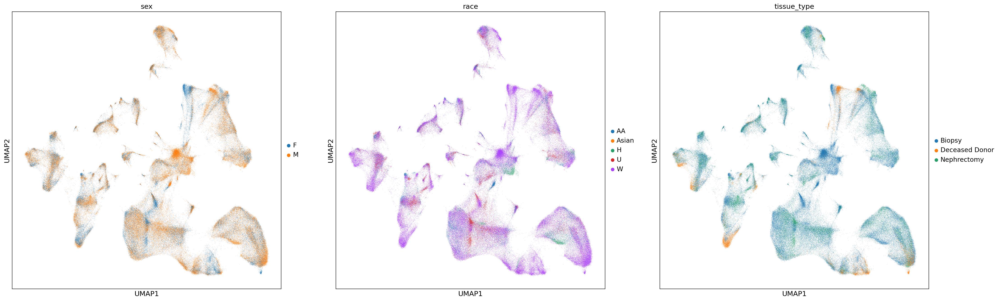

In [11]:
sc.pl.umap(adata, color=['sex', 'race', 'tissue_type'])

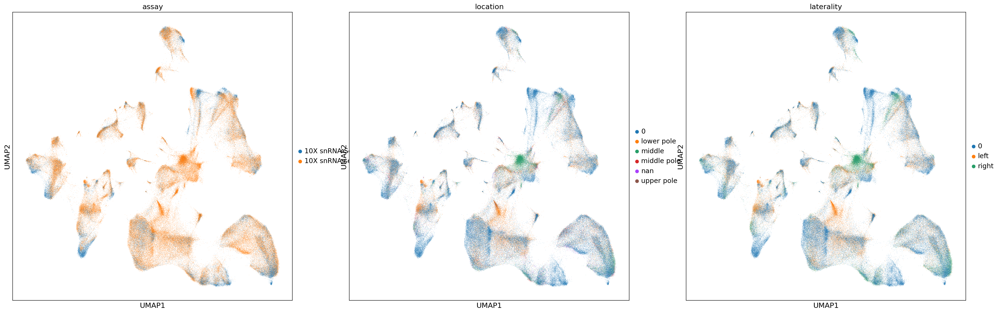

In [12]:
sc.pl.umap(adata, color=['assay', 'location', 'laterality'])

In [13]:
adata.layers['counts'] = adata.X.copy()

In [14]:
categorical_covariate_keys = ['library', 'specimen', 'experiment_short',
                              'specimen', 'condition_long', 'patient',
                              'sex', 'race', 'tissue_type',
                              'assay', 'location', 'laterality']

# convert to categorial
adata.obs['library'] = adata.obs['library'].astype("category")
adata.obs['specimen'] = adata.obs['specimen'].astype("category")
adata.obs['experiment_short'] = adata.obs['experiment_short'].astype("category")
adata.obs['condition_long'] = adata.obs['condition_long'].astype("category")
adata.obs['patient'] = adata.obs['patient'].astype("category")
adata.obs['sex'] = adata.obs['sex'].astype("category")
adata.obs['race'] = adata.obs['race'].astype("category")
adata.obs['tissue_type'] = adata.obs['tissue_type'].astype("category")
adata.obs['assay'] = adata.obs['assay'].astype("category")
adata.obs['location'] = adata.obs['location'].astype("category")
adata.obs['laterality'] = adata.obs['laterality'].astype("category")

In [ ]:
for subclass in ["subclass_l1", "subclass_l2"]:
    os.makedirs(f"{out_dir}/{subclass}", exist_ok=True)
    
    adata_ref = adata.copy()

    RegressionModel.setup_anndata(adata=adata_ref, labels_key=subclass,
                                  batch_key='patient',
                                  categorical_covariate_keys=['library'])
    
    mod = RegressionModel(adata_ref)

    # view anndata_setup as a sanity check
    mod.view_anndata_setup()

    mod.train(max_epochs=250)

    # In this section, we export the estimated cell abundance (summary of the posterior distribution).
    adata_ref = mod.export_posterior(
        adata_ref, sample_kwargs={'num_samples': 1000, 'batch_size': 2500}
    )

    # Save model
    mod.save(f"{out_dir}/{subclass}", overwrite=True)

    # export estimated expression in each cluster
    if 'means_per_cluster_mu_fg' in adata_ref.varm.keys():
        inf_aver = adata_ref.varm['means_per_cluster_mu_fg'][[f'means_per_cluster_mu_fg_{i}'
                                        for i in adata_ref.uns['mod']['factor_names']]].copy()
    else:
        inf_aver = adata_ref.var[[f'means_per_cluster_mu_fg_{i}'
                                        for i in adata_ref.uns['mod']['factor_names']]].copy()
    inf_aver.columns = adata_ref.uns['mod']['factor_names']
    inf_aver.to_csv(f"{out_dir}/{subclass}/inf_aver.csv")

/data/pinello/SHARED_SOFTWARE/envs/zl002_envs/zl_cell2location/lib/python3.10/site-packages/scvi/data/fields/_layer_field.py:115: UserWarning: Training will be faster when sparse matrix is formatted as CSR. It is safe to cast before model initialization.
  _verify_and_correct_data_format(adata, self.attr_name, self.attr_key)


Anndata setup with scvi-tools version 1.3.3.

Setup via `RegressionModel.setup_anndata` with arguments:

{
│   'layer': None,
│   'batch_key': 'patient',
│   'labels_key': 'subclass_l1',
│   'categorical_covariate_keys': ['library'],
│   'continuous_covariate_keys': None
}

         Summary Statistics          
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓
┃     Summary Stat Key     ┃ Value  ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩
│         n_batch          │   36   │
│         n_cells          │ 200338 │
│ n_extra_categorical_covs │   1    │
│ n_extra_continuous_covs  │   0    │
│         n_labels         │   16   │
│          n_vars          │ 29732  │
└──────────────────────────┴────────┘

...

                    batch State Registry                     
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃   Source Location    ┃  Categories  ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['patient'] │    18-142    │          0          │
│                      │    18-162    │          1          │
│                      │    18-312    │          2          │
│                      │   29-10006   │          3          │
│                      │   29-10008   │          4          │
│                      │   29-10010   │          5          │
│                      │   29-10012   │          6          │
│                      │   29-10013   │          7          │
│                      │   30-10034   │          8          │
│                      │   31-10000   │          9          │
│                      │   31-10001   │         10          │
│                      │   31-10006   │         11          │
│                      │   31-10013   │         12          │
│                      │   31-10035   │         13          │
│                      │     32-2     │         14          │
│                      │   32-10003   │         15          │
│                      │   32-10034   │         16          │
│                      │   33-10005   │         17          │
│                      │   33-10006   │         18          │
│                      │     3477     │         19          │
│                      │     3479     │         20          │
│                      │     3487     │         21          │
│                      │     3490     │         22          │
│                      │     3499     │         23          │
│                      │     3504     │         24          │
│                      │     3535     │         25          │
│                      │     3593     │         26          │
│                      │     3613     │         27          │
│                      │ COV-02-0002  │         28          │
│                      │ COV-02-0010  │         29          │
│                      │ COV-02-0094  │         30          │
│                      │ COV-02-0096  │         31          │
│                      │    KRP446    │         32          │
│                      │    KRP460    │         33          │
│                      │    KRP461    │         34          │
│                      │    KRP462    │         35          │
└──────────────────────┴──────────────┴─────────────────────┘

                     labels State Registry                     
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃     Source Location      ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['subclass_l1'] │    ATL     │          0          │
│                          │    CNT     │          1          │
│                          │    DCT     │          2          │
│                          │    DTL     │          3          │
│                          │     EC     │          4          │
│                          │    FIB     │          5          │
│                          │     IC     │          6          │
│                          │    IMM     │          7          │
│                          │    NEU     │          8          │
│                          │     PC     │          9          │
│                          │    PEC     │         10          │
│                          │    POD     │         11          │
│                          │     PT     │         12          │
│                          │    PapE    │         13          │
│                          │    TAL     │         14          │
│                          │   VSM/P    │         15          │
└──────────────────────────┴────────────┴─────────────────────┘

           extra_categorical_covs State Registry           
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃   Source Location    ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['library'] │    KB1     │          0          │
│                      │    KB2     │          1          │
│                      │    KB3     │          2          │
│                      │    KB4     │          3          │
│                      │    KB5     │          4          │
│                      │    KB6     │          5          │
│                      │    KB7     │          6          │
│                      │    KB8     │          7          │
│                      │    KB9     │          8          │
│                      │    KB10    │          9          │
│                      │    KB11    │         10          │
│                      │    KB12    │         11          │
│                      │    KB13    │         12          │
│                      │    KB14    │         13          │
│                      │    KB15    │         14          │
│                      │    KB16    │         15          │
│                      │   KBCVD1   │         16          │
│                      │   KBCVD2   │         17          │
│                      │   KBCVD3   │         18          │
│                      │   KBCVD4   │         19          │
│                      │    KC33    │         20          │
│                      │    KC34    │         21          │
│                      │    KC35    │         22          │
│                      │    KC36    │         23          │
│                      │    KC39    │         24          │
│                      │    KC40    │         25          │
│                      │    KC77    │         26          │
│                      │    KC78    │         27          │
│                      │    KC79    │         28          │
│                      │    KC82    │         29          │
│                      │    KC83    │         30          │
│                      │    KC84    │         31          │
│                      │    KM69    │         32          │
│                      │    KM71    │         33          │
│                      │    KM72    │         34          │
│                      │   KM102    │         35          │
│                      │   KM103    │         36          │
│                      │    PA1     │         37          │
│                      │    PA3     │         38          │
│                      │    PA4     │         39          │
│                      │    PA5     │         40          │
│                      │    dKC1    │         41          │
│                      │    dKC2    │         42          │
│                      │    dKC3    │         43          │
│                      │            │                     │
└──────────────────────┴────────────┴─────────────────────┘

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/data/pinello/SHARED_SOFTWARE/envs/zl002_envs/zl_cell2location/lib/python3.10/site-packages/lightning/pytorch/trainer/configuration_validator.py:68: You passed in a `val_dataloader` but have no `validation_step`. Skipping val loop.
You are using a CUDA device ('NVIDIA A100 80GB PCIe') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK

Epoch 2/250:   0%|          | 1/250 [01:36<6:41:58, 96.86s/it, v_num=1]